# Raisin Dataset

## 1. Overview
- **Source:** [UCI Machine Learning Repository — Raisin Dataset](https://archive.ics.uci.edu/dataset/850/raisin)
- **Samples:** 900 instances (450 *Kecimen*, 450 *Besni*)
- **Task:** Binary Classification based on morphological/geometric properties

---

## 2. Feature Descriptions

# Raisin Dataset Documentation

## Overview
* **Source:** [UCI Machine Learning Repository - Raisin Dataset](https://archive.ics.uci.edu/dataset/850/raisin)
* **Task:** Binary Classification (Distinguishing between **Kecimen** and **Besni** raisin varieties)
* **Dataset Size:** 900 instances (balanced: 450 Kecimen, 450 Besni)
* **Input Features:** 7 continuous numerical features extracted via morphological image processing
* **Target Feature:** `Class` (`Kecimen` vs. `Besni`)

---

## Feature Dictionary

| Feature | Data Type | Description |
| :--- | :--- | :--- |
| **Area** | Integer | Total number of pixels within the boundaries of the raisin grain. |
| **MajorAxisLength** | Float | Length of the longest line along the grain's equivalent ellipse. |
| **MinorAxisLength** | Float | Width of the grain perpendicular to the major axis. |
| **Eccentricity** | Float | Measure of elongation / deviation from circularity ($0 \le e < 1$). |
| **ConvexArea** | Integer | Number of pixels in the smallest convex hull enclosing the raisin. |
| **Extent** | Float | Ratio of the raisin contour area to its bounding box area. |
| **Perimeter** | Float | Circumference length of the raisin boundary in pixels. |
| **Class** | String | Target category: `Kecimen` or `Besni`. |

In [302]:
from pathlib import Path 
import os
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn


In [303]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

# Data Loading & Understanding

In [304]:
ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "Raisin_Dataset.xlsx"

data = pd.read_excel(DATA_PATH)

In [305]:
display(data.head())
display(data.columns)
display(data.shape)

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='str')

(900, 8)

In [306]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    str    
dtypes: float64(5), int64(2), str(1)
memory usage: 56.4 KB
None


In [307]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,900.0,87804.127778,39002.111390,25387.000000,59348.000000,78902.000000,105028.250000,235047.000000
MajorAxisLength,900.0,430.929950,116.035121,225.629541,345.442898,407.803951,494.187014,997.291941
MinorAxisLength,900.0,254.488133,49.988902,143.710872,219.111126,247.848409,279.888575,492.275279
Eccentricity,900.0,0.781542,0.090318,0.348730,0.741766,0.798846,0.842571,0.962124
ConvexArea,900.0,91186.090000,40769.290132,26139.000000,61513.250000,81651.000000,108375.750000,278217.000000
Extent,900.0,0.699508,0.053468,0.379856,0.670869,0.707367,0.734991,0.835455
Perimeter,900.0,1165.906636,273.764315,619.074000,966.410750,1119.509000,1308.389750,2697.753000


In [308]:
data.isnull().sum()

Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

In [309]:
data.duplicated().sum()

np.int64(0)

In [310]:
display(data['Class'].value_counts())

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

In [311]:
# separate x--> data, and y-->target
X = data.drop(columns='Class')
y = data['Class']

display(X.head())
display(y.sample(5))

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251


212    Kecimen
132    Kecimen
49     Kecimen
689      Besni
53     Kecimen
Name: Class, dtype: str

# Data Processing

In [312]:
# Encode the target
mapping = {"Kecimen" : 0, "Besni" : 1}
y = y.map(mapping)

# Separate train and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, shuffle= True, random_state=42)

# Standardizing 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


display(
    pd.DataFrame(
        X_train_scaled,
        columns=data.columns[:-1]
        ).head()
    )

display(
    pd.DataFrame(
        X_test_scaled,
        columns=data.columns[: -1]
        ).head()
    )


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,-0.197548,0.148973,-0.446384,0.810345,-0.174590,-0.455165,0.027250
1,-0.400089,-0.841955,0.549999,-2.715357,-0.407115,0.126449,-0.426825
2,-0.062537,-0.446118,0.660317,-1.420652,-0.111247,1.145542,-0.271681
3,2.408729,1.628445,2.464265,0.106312,2.376421,0.615881,1.866175
4,-0.645767,-0.094676,-1.260732,1.193980,-0.664665,1.582399,-0.549742


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,0.182122,0.166817,0.501427,0.022107,0.186992,-0.442049,0.315980
1,-0.670569,-0.742670,-0.384946,-0.541211,-0.591742,0.055437,-0.384902
2,-0.904024,-1.280522,-0.252700,-2.869185,-0.897948,0.701242,-0.998923
3,0.626751,0.950506,0.243715,0.966509,0.619663,0.799672,0.810321
4,-0.975604,-1.248133,-0.647017,-1.624475,-0.995210,1.222492,-1.189048


In [ ]:
# convert data into torch tensor

## Features
X_train_tensor = torch.from_numpy(X_train_scaled).to(torch.float32)
X_test_tensor = torch.from_numpy(X_test_scaled).to(torch.float32)

## Target
### From Numpy--> ndarray to torch-->tensor
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)           # unsqueeze to convert the shape of y from 1D [720] to 2D [720, 1], for the loss i will use BCEWithLogisticLoss

y_train_tensor.dtype, y_test_tensor.dtype

(torch.float32, torch.float32)

# Dataset & DataLoader

In [314]:
# Custom Dataset Class
class RaisinDataset(Dataset):
    def __init__(self, X, y):
        self.X  = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


train_dataset = RaisinDataset(X_train_tensor, y_train_tensor)
test_dataset = RaisinDataset(X_test_tensor, y_test_tensor)

In [315]:
# DataLoader
train_loader = DataLoader(train_dataset, batch_size= 64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [316]:
# Check one batch
features_batch, labels_batch = next(iter(train_loader))

print(f"Features shape: {features_batch.shape}")
print(f"Features dtype: {features_batch.dtype}")

print(f"\nLabels shape: {labels_batch.shape}")
print(f"Labels dtype: {labels_batch.dtype}")

Features shape: torch.Size([64, 7])
Features dtype: torch.float32

Labels shape: torch.Size([64, 1])
Labels dtype: torch.float32


# Build Neural Network

In [317]:
# Custom Model Class
class RaisinClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        # 1. Input Layer (7) --> Hidden Layer (16)
        self.layer1 = nn.Linear(in_features=7, out_features=16)
        self.relu = nn.ReLU()

        # 2. Hidden Layer1 (16) --> Hidden Layer2 (8)
        self.layer2 = nn.Linear(in_features=16, out_features=8)

        # 3. Hidden Layer2 (8) --> Output Layer (1)
        self.layer3 = nn.Linear(in_features=8, out_features=1)

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.layer3(x)

        return x
        

In [318]:
# Instantiate The Model
model = RaisinClassifier()
print(model)

# Number of trainable parameters
total_learnable_params = sum(p.numel() for p in model.parameters() if p.requires_grad == True)
print(f"\nTotal Learnable/Trainable Parameters = {total_learnable_params}")

RaisinClassifier(
  (layer1): Linear(in_features=7, out_features=16, bias=True)
  (relu): ReLU()
  (layer2): Linear(in_features=16, out_features=8, bias=True)
  (layer3): Linear(in_features=8, out_features=1, bias=True)
)

Total Learnable/Trainable Parameters = 273


In [319]:
# Pass a sample batch through the model
features_batch, labels_batch = next(iter(train_loader))

sample = model(features_batch)          # calling model direct not model.forward(x), to activate pytorch hooks

print(f"Input batch shape:   {features_batch.shape}")
print(f"Sample output shape: {sample.shape}")

Input batch shape:   torch.Size([64, 7])
Sample output shape: torch.Size([64, 1])


In [320]:
# Loss_fn
criterion = nn.BCEWithLogitsLoss()

# move model to GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# Optimizer
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001, weight_decay=0.0001)

print(f"Model device: {next(model.parameters()).device}")

Model device: cuda:0


# Training & Testing Functions

In [321]:
# Train Function
def train_step(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device
) -> tuple[float, float]:
    """Performs a single training epoch over the dataloader."""
    model.train()
    
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in dataloader:
        features, labels = features.to(device), labels.to(device)

        # 1. Forward pass
        outputs = model(features)
        
        # 2. Calculate loss
        loss = loss_fn(outputs, labels)

        # 3. Zero gradients
        optimizer.zero_grad(set_to_none=True)

        # 4. Backward pass
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # 6. Metrics calculation (logits >= 0.0 is equivalent to sigmoid >= 0.5)
        predicted = (outputs >= 0.0).float()
        total_correct += (predicted == labels).sum().item()
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    return epoch_loss, epoch_acc

In [322]:
# Test Function 
def test_step(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    device: torch.device
) -> tuple[float, float]:
    """Performs an evaluation step over the test dataloader."""
    model.eval()
    
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for features, labels in dataloader:
            features, labels = features.to(device), labels.to(device)

            # 1. Forward pass
            outputs = model(features)
            
            # 2. Calculate loss
            loss = loss_fn(outputs, labels)

            # 3. Metrics calculation
            predicted = (outputs >= 0.0).float()
            total_correct += (predicted == labels).sum().item()
            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    return epoch_loss, epoch_acc

# Model Training, Saving, and Eval

In [323]:
# Train & Save Best Model
epochs = 80
train_losses = []
test_losses = []
best_loss = float("inf")

torch.manual_seed(42)
for epoch in range(epochs):
    train_loss, train_acc = train_step(
        model=model,
        dataloader=train_loader,
        loss_fn=criterion,
        optimizer=optimizer,
        device=device
    )
    
    test_loss, test_acc = test_step(
        model=model,
        dataloader=test_loader,
        loss_fn=criterion,
        device=device
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    # Save best model
    if test_loss < best_loss:
        best_loss = test_loss
        torch.save(model.state_dict(), "best_model.pth")

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

Epoch 10 | Train Loss: 0.5032, Acc: 0.8611 | Test Loss: 0.4691, Acc: 0.8611
Epoch 20 | Train Loss: 0.3477, Acc: 0.8681 | Test Loss: 0.3292, Acc: 0.8611
Epoch 30 | Train Loss: 0.3406, Acc: 0.8708 | Test Loss: 0.3274, Acc: 0.8611
Epoch 40 | Train Loss: 0.3363, Acc: 0.8736 | Test Loss: 0.3279, Acc: 0.8611
Epoch 50 | Train Loss: 0.3323, Acc: 0.8722 | Test Loss: 0.3263, Acc: 0.8667
Epoch 60 | Train Loss: 0.3286, Acc: 0.8722 | Test Loss: 0.3253, Acc: 0.8667
Epoch 70 | Train Loss: 0.3252, Acc: 0.8722 | Test Loss: 0.3242, Acc: 0.8667
Epoch 80 | Train Loss: 0.3223, Acc: 0.8764 | Test Loss: 0.3234, Acc: 0.8667


In [324]:
# Load the best model checkpoint
model.load_state_dict(torch.load("best_model.pth", weights_only=True))
model.eval()

y_true = []
y_preds = []
y_probs = []
total_loss = 0.0
total_samples = 0

with torch.inference_mode():
    for features, labels in test_loader:
        features, labels = features.to(device), labels.to(device)

        # Forward pass
        logits = model(features)
        loss = criterion(logits, labels)

        # Convert logits -> probabilities -> binary predictions (threshold 0.5)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()

        # Accumulate loss
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

        # Collect labels and predictions
        y_true.append(labels.cpu())
        y_probs.append(probs.cpu())
        y_preds.append(preds.cpu())

# Concatenate batches into single arrays
test_loss = total_loss / total_samples
y_true = torch.cat(y_true).numpy().flatten()
y_probs = torch.cat(y_probs).numpy().flatten()
y_preds = torch.cat(y_preds).numpy().flatten()

Test Loss : 0.3234
Accuracy  : 0.8667
Precision : 0.8523
Recall    : 0.8721
F1-Score  : 0.8621


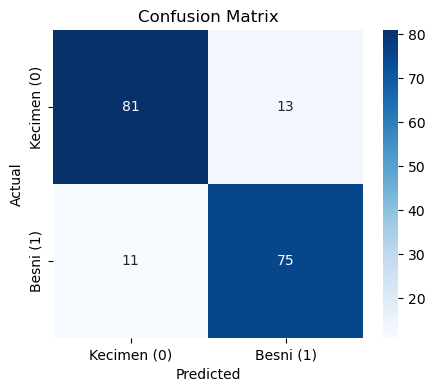

In [325]:
# Calculate metrics
test_acc = accuracy_score(y_true, y_preds)
precision = precision_score(y_true, y_preds)
recall = recall_score(y_true, y_preds)
f1 = f1_score(y_true, y_preds)
cm = confusion_matrix(y_true, y_preds)

print(f"Test Loss : {test_loss:.4f}")
print(f"Accuracy  : {test_acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Kecimen (0)", "Besni (1)"],
            yticklabels=["Kecimen (0)", "Besni (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [326]:
# Put results in a DataFrame for easy inspection
results_df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_preds,
    "Probability": y_probs.round(4)
})

print("Sample Correct Predictions:")
display(results_df[results_df["Actual"] == results_df["Predicted"]].head(5))

print("\nSample Incorrect Predictions:")
display(results_df[results_df["Actual"] != results_df["Predicted"]].head(5))

Sample Correct Predictions:


,Actual,Predicted,Probability
2,0.0,0.0,0.0432
3,1.0,1.0,0.9807
4,0.0,0.0,0.0340
6,0.0,0.0,0.0341
7,0.0,0.0,0.3406



Sample Incorrect Predictions:


,Actual,Predicted,Probability
0,0.0,1.0,0.7953
1,1.0,0.0,0.1703
5,1.0,0.0,0.3837
10,0.0,1.0,0.8902
16,0.0,1.0,0.6344


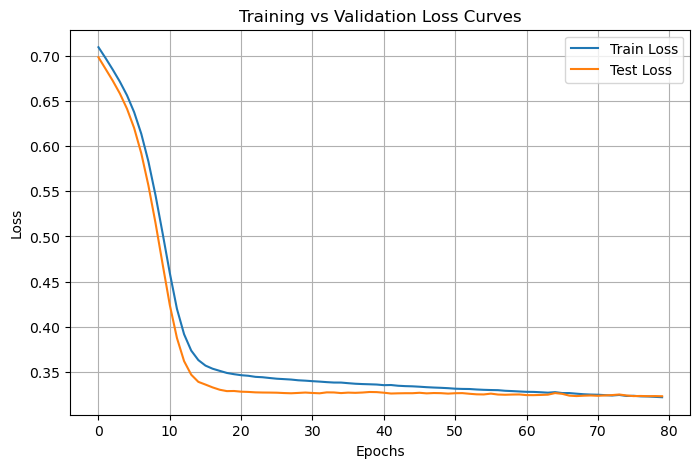

In [327]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss Curves")
plt.legend()
plt.grid(True)
plt.show()